# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 8  # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import inspect
import sys
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, (
    "Впишите свой номер варианта: целое число от 1 до 22"
)
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = (
    sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
)
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError(
                "Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                "в остальных случаях проверьте подключение к сети."
            ) from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: /home/kerty/Projects/cv-2026-kabakov/data
Вариант 08 уже на месте: /home/kerty/Projects/cv-2026-kabakov/data/variant_08
данные варианта: /home/kerty/Projects/cv-2026-kabakov/data/variant_08
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import json
import xml.etree.ElementTree as ET

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 4.14.0 | numpy 2.5.4 | pandas 3.1.0


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [3]:
# TODO: прочитайте variant.json и напечатайте его.
# Подсказка: путь собирайте от DATA_DIR, это объект Path, а не строка:
#   (DATA_DIR / "variant.json").read_text(encoding="utf-8") даёт текст файла,
#   json.loads(...) превращает текст в словарь.
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(variant_info)

# TODO: прочитайте labels.csv в DataFrame labels и покажите первые строки.
# Путь к файлу: DATA_DIR / "labels.csv"
pd.set_option("expand_frame_repr", False)
labels = pd.read_csv(DATA_DIR / "labels.csv")
print(labels[:5])


{'variant': 8, 'dataset_version': 'v1', 'source': 'release', 'breeds': ['Maine_Coon', 'Ragdoll', 'american_pit_bull_terrier', 'staffordshire_bull_terrier'], 'species': {'Maine_Coon': 'cat', 'Ragdoll': 'cat', 'american_pit_bull_terrier': 'dog', 'staffordshire_bull_terrier': 'dog'}, 'class_ids': {'Maine_Coon': 0, 'Ragdoll': 1, 'american_pit_bull_terrier': 2, 'staffordshire_bull_terrier': 3}, 'names_ru': {'Maine_Coon': 'мейн-кун', 'Ragdoll': 'рэгдолл', 'american_pit_bull_terrier': 'американский питбультерьер', 'staffordshire_bull_terrier': 'стаффордширский бультерьер'}, 'n_images': 799, 'n_boxes': 405, 'n_trimaps': 799, 'per_breed': {'Maine_Coon': {'images': 201, 'boxes': 100, 'trimaps': 201}, 'Ragdoll': {'images': 203, 'boxes': 102, 'trimaps': 203}, 'american_pit_bull_terrier': {'images': 203, 'boxes': 103, 'trimaps': 203}, 'staffordshire_bull_terrier': {'images': 192, 'boxes': 100, 'trimaps': 192}}, 'dataset': 'Oxford-IIIT Pet', 'dataset_url': 'https://www.robots.ox.ac.uk/~vgg/data/pets

## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [4]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[
            16:48, 16:48
        ]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)

# TODO: прочитайте файл через cv2.imread(str(example_path)) в переменную bgr
# TODO: напечатайте type, shape, dtype, min, max и значение пикселя в центре кадра
#       bgr[bgr.shape[0] // 2, bgr.shape[1] // 2]
bgr = cv2.imread(str(example_path))
print(f"{type(bgr) = }")
print(f"{bgr.shape = }")
print(f"{bgr.dtype = }")
print(f"{bgr.min() = }")
print(f"{bgr.max() = }")
print(f"{bgr[bgr.shape[0]//2, bgr.shape[1]//2] = }")


Maine_Coon_69.jpg
type(bgr) = <class 'numpy.ndarray'>
bgr.shape = (333, 500, 3)
bgr.dtype = dtype('uint8')
bgr.min() = np.uint8(0)
bgr.max() = np.uint8(255)
bgr[bgr.shape[0]//2, bgr.shape[1]//2] = array([ 5, 27, 62], dtype=uint8)


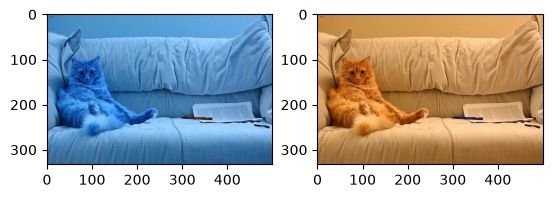

In [17]:
# TODO: переведите bgr в rgb через cv2.cvtColor(..., cv2.COLOR_BGR2RGB)
# TODO: покажите bgr и rgb рядом. Что случилось с цветами?
# Ответ: синий и красный поменялись местами
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
plt.subplot(1, 2, 1)
plt.imshow(bgr)
plt.subplot(1, 2, 2)
plt.imshow(rgb)
plt.show()


In [18]:
print(f"{bgr[bgr.shape[0]//2, bgr.shape[1]//2] = }")
print(f"{rgb[rgb.shape[0]//2, rgb.shape[1]//2] = }")


bgr[bgr.shape[0]//2, bgr.shape[1]//2] = array([ 5, 27, 62], dtype=uint8)
rgb[rgb.shape[0]//2, rgb.shape[1]//2] = array([62, 27,  5], dtype=uint8)


Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [6]:
# TODO: получите gray, resized (224x224) и flipped, напечатайте их shape
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)

In [7]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)  # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


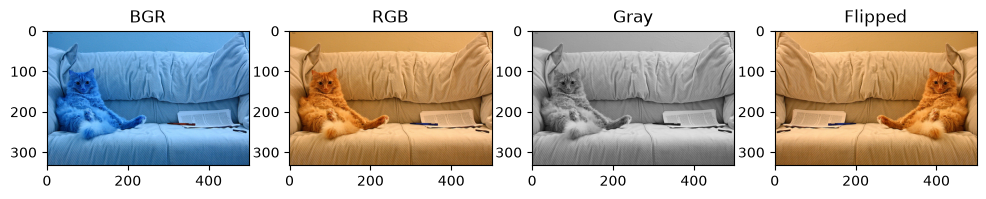

In [8]:
# TODO: 4 панели на одной фигуре: BGR как есть, RGB, серое, отражение
plt.figure(figsize=(12, 3))

plt.subplot(1, 4, 1)
plt.imshow(bgr)
plt.title("BGR")

plt.subplot(1, 4, 2)
plt.imshow(rgb)
plt.title("RGB")

plt.subplot(1, 4, 3)
plt.imshow(gray, cmap="gray")
plt.title("Gray")

plt.subplot(1, 4, 4)
plt.imshow(flipped)
plt.title("Flipped")

plt.savefig(RESULTS / "transforms.png", dpi=110)


## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [9]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    # TODO: через Image.open(p) запишите pil_format, mode, width, height
    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"] = im.width
        rec["height"] = im.height

    # TODO: has_xml: существует ли XML_DIR / (p.stem + ".xml")
    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()

    # TODO: breed и species из label_by_file.loc[p.name]
    rec["breed"] = label_by_file.loc[p.name].breed
    rec["species"] = label_by_file.loc[p.name].species

    rows.append(rec)

info = pd.DataFrame(rows)
info.head()

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Maine_Coon_1.jpg,.jpg,JPEG,RGB,174,226,True,Maine_Coon,cat
1,Maine_Coon_10.jpg,.jpg,JPEG,RGB,600,900,True,Maine_Coon,cat
2,Maine_Coon_100.jpg,.jpg,JPEG,RGB,500,357,True,Maine_Coon,cat
3,Maine_Coon_101.jpg,.jpg,JPEG,RGB,444,500,True,Maine_Coon,cat
4,Maine_Coon_102.jpg,.jpg,JPEG,RGB,320,500,True,Maine_Coon,cat


In [ ]:
# TODO: соберите словарь summary с главными числами и сохраните в results/summary.csv
# Минимум: число файлов, пород, кошек и собак, min/медиана/max ширины и высоты,
# сколько не RGB, сколько .jpg на самом деле не JPEG, сколько с XML.
summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
    "n_cats": (info["species"] == "cat").sum(),
    "n_dogs": (info["species"] == "dog").sum(),
    "width_min": info["width"].min(),
    "width_median": info["width"].median(),
    "width_max": info["width"].max(),
    "height_min": info["height"].min(),
    "height_median": info["height"].median(),
    "height_max": info["height"].max(),
    "n_formats": info["pil_format"].nunique(),
    "n_non_jpeg": (info["pil_format"] != "JPEG").sum(),
    "n_modes": info["mode"].nunique(),
    "n_non_rgb": (info["mode"] != "RGB").sum(),
    "n_jpg_not_jpeg": ((info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")).sum(),
    "n_with_xml": info["has_xml"].sum(),
}
summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df

,metric,value
0,variant,8.0
1,n_files,799.0
2,n_breeds,4.0
3,n_cats,404.0
4,n_dogs,395.0
5,width_min,119.0
6,width_median,500.0
7,width_max,1024.0
8,height_min,174.0
9,height_median,375.0


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [11]:
# TODO: напечатайте файлы с mode != "RGB" и файлы с pil_format != "JPEG"
print(info[info["mode"] != "RGB"])
print()
print(info[info["pil_format"] != "JPEG"])

                              filename   ext pil_format mode  width  height  has_xml                       breed species
707   staffordshire_bull_terrier_2.jpg  .jpg       JPEG    L    500     282    False  staffordshire_bull_terrier     dog
713  staffordshire_bull_terrier_22.jpg  .jpg       JPEG    L    364     500    False  staffordshire_bull_terrier     dog

Empty DataFrame
Columns: [filename, ext, pil_format, mode, width, height, has_xml, breed, species]
Index: []


In [12]:
# TODO: сравните формы массивов для одного проблемного файла
p = IMG_DIR / info[info["mode"] != "RGB"].iloc[0, 0]
print(f"{cv2.imread(p).shape = }")
print(f"{cv2.imread(p, cv2.IMREAD_UNCHANGED).shape = }")

cv2.imread(p).shape = (282, 500, 3)
cv2.imread(p, cv2.IMREAD_UNCHANGED).shape = (282, 500)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [32]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [
        tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
        for bb in root.iter("bndbox")
    ]


# TODO: возьмите одно изображение с XML и напечатайте его боксы
stem = Path(info[info["has_xml"]].iloc[0, 0]).stem
xml = XML_DIR / (stem + ".xml")
print(f"{read_boxes(xml) = }")
# TODO: прочитайте его trimap: cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
#       и выведите np.unique(trimap)
trimap = cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
print(f"{np.unique(trimap) = }")

read_boxes(xml) = [(62, 7, 129, 68)]
np.unique(trimap) = array([1, 2, 3], dtype=uint8)


In [ ]:
box_count = {}
for _, row in info[info["has_xml"]].iterrows():
    boxes = len(read_boxes(XML_DIR / (Path(row["filename"]).stem + ".xml")))
    box_count[boxes] = box_count.get(boxes, 0) + 1
print(f"{box_count = }")

box_count = {1: 405}


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

                                                    filename   ext pil_format mode  width  height  has_xml species
breed                                                                                                             
Maine_Coon                                  Maine_Coon_1.jpg  .jpg       JPEG  RGB    174     226     True     cat
Ragdoll                                        Ragdoll_1.jpg  .jpg       JPEG  RGB    183     275     True     cat
american_pit_bull_terrier   american_pit_bull_terrier_10.jpg  .jpg       JPEG  RGB    500     368     True     dog
staffordshire_bull_terrier  staffordshire_bull_terrier_1.jpg  .jpg       JPEG  RGB    299     500     True     dog


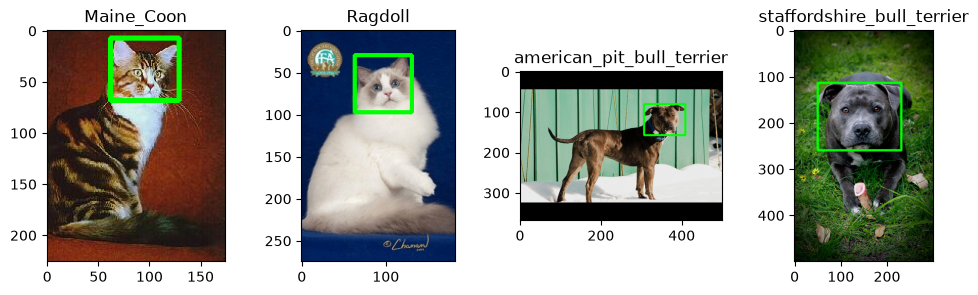

In [14]:
# TODO: для каждой породы возьмите одно фото с XML, нарисуйте бокс,
#       покажите все фото в один ряд через plt.subplot и сохраните в results/samples_grid.png
samples = (
    info[info["has_xml"] & (info["mode"] == "RGB")].groupby("breed", sort=True).first()
)
print(samples)

plt.figure(figsize=(12, 3))
for i, (breed, row) in enumerate(samples.iterrows(), 1):
    rgb = cv2.cvtColor(cv2.imread(IMG_DIR / row["filename"]), cv2.COLOR_BGR2RGB)
    for x0, y0, x1, y1 in read_boxes(XML_DIR / (Path(row["filename"]).stem + ".xml")):
        cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)

    plt.subplot(1, len(samples), i)
    plt.imshow(rgb)
    plt.title(breed)

plt.savefig(RESULTS / "samples_grid.png", dpi=110)

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [15]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

        metric  value
       variant    8.0
       n_files  799.0
      n_breeds    4.0
        n_cats  404.0
        n_dogs  395.0
     width_min  119.0
  width_median  500.0
     width_max 1024.0
    height_min  174.0
 height_median  375.0
    height_max  900.0
     n_formats    1.0
    n_non_jpeg    0.0
       n_modes    2.0
     n_non_rgb    2.0
n_jpg_not_jpeg    0.0
    n_with_xml  405.0
не хватает: ничего, все 3 файла на месте


In [ ]:
import shutil

if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files

        files.download(archive)